# Análise exploratória com foco em negócio

Este notebook responde a quatro perguntas de negócio: que fatores pesam mais na satisfação, o que mais gera detratores, se existe um ponto de ruptura na experiência do cliente e que tipo de cliente tende a ter NPS mais alto ou mais baixo. A análise usa a base tratada, só com os pedidos de treino: os de teste ficam reservados para avaliar o modelo e as regras simples sem viés (D-11).

Três regras valem para todo o notebook. Grupos se comparam pela proporção de detratores e pelo NPS, nunca pela nota média (D-02). Os achados descrevem associação, não causa. E, como a base é simulada (D-10), cada padrão vale para esta base e entra nas recomendações como hipótese a validar com dados reais.

In [1]:
# Importações
from functools import partial
import textwrap

from loguru import logger
from matplotlib.patches import Patch
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.tree import DecisionTreeClassifier
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.proportion import proportion_confint

# Logs do projeto desligados para não gravar caminhos da máquina local nas saídas
logger.disable("src")

from src.analysis import (
    bootstrap_statistic,
    breakpoint_test,
    estimate_contrast,
    excess_over_additive,
    factor_ranking,
    failure_flags,
    invert_verdict,
    nps_gain,
    nps_of,
    problem_impact,
    quartiles,
    ranking_metrics,
    rate_table,
    standardized_share,
    tree_leaves,
    verdict_adjustment,
    verdict_breakpoint,
    verdict_effect,
    verdict_share,
    within_strata,
)
from src.config import RANDOM_SEED
from src.features import LONG_RESOLUTION_DAYS, classify_nps, load_processed_data
from src.plots import (
    ACCENT,
    CATEGORY_COLORS,
    plot_impact_frequency,
    plot_rate,
    plot_rate_heatmaps,
    plot_rates,
    save_figure,
    set_style,
)
from src.split import TRAIN, split_train_test

set_style()

# Só os pedidos de treino; o teste fica intocado até a avaliação do modelo (D-11)
processed = load_processed_data()
train = processed[split_train_test(processed) == TRAIN].copy()
print(f"{len(train)} pedidos de treino, de {len(processed)}")


2000 pedidos de treino, de 2500


## 1. A variável-alvo

Distribuição da nota, proporção de detratores, neutros e promotores e NPS do treino. A proporção de detratores também fixa as referências das métricas da D-03: um modelo que dá o mesmo risco a todos tem PR-AUC igual a ela, e a captura numa lista com os 20% de maior risco tem um teto, porque a lista não comporta todos os detratores quando eles passam de 20% dos pedidos.

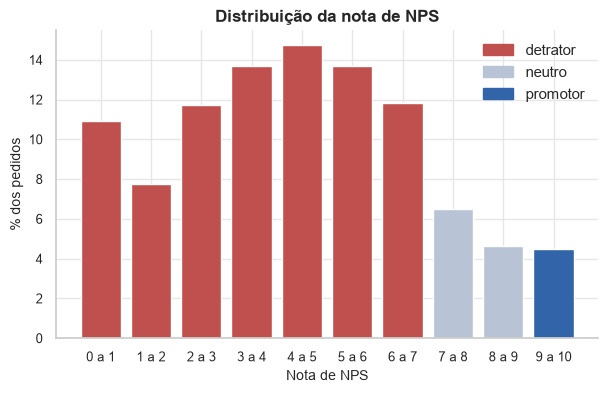

detratores (%)                 84.35
neutros (%)                    11.15
promotores (%)                  4.50
NPS                           -79.85
PR-AUC do modelo ingênuo        0.84
teto da captura no topo (%)    23.71
dtype: float64

In [2]:
# Nota em faixas de um ponto, coloridas pela categoria do NPS (D-05)
score_band = np.floor(train["nps_score"]).clip(upper=9).astype(int)
share_by_band = score_band.value_counts(normalize=True).sort_index().mul(100)
band_category = classify_nps(share_by_band.index.to_series())

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(share_by_band.index, share_by_band, color=band_category.map(CATEGORY_COLORS).tolist())
ax.set_xticks(share_by_band.index, [f"{band} a {band + 1}" for band in share_by_band.index])
ax.set_xlabel("Nota de NPS")
ax.set_ylabel("% dos pedidos")
ax.set_title("Distribuição da nota de NPS")
ax.legend(handles=[Patch(color=c, label=n) for n, c in CATEGORY_COLORS.items()], frameon=False)
save_figure(fig, "01_distribuicao_da_nota")
plt.show()

shares = train["nps_category"].value_counts(normalize=True).mul(100)
prevalence = train["is_detractor"].mean()
pd.Series(
    {
        "detratores (%)": shares["detrator"],
        "neutros (%)": shares["neutro"],
        "promotores (%)": shares["promotor"],
        "NPS": nps_of(train["nps_category"]),
        "PR-AUC do modelo ingênuo": prevalence,
        "teto da captura no topo (%)": 100 * min(1, 0.2 / prevalence),
    }
).round(2)


**A insatisfação é generalizada: mais de oito em cada dez clientes do treino dão nota abaixo de 7, e o NPS fica perto do piso da escala.** As notas se espalham por toda a faixa de detrator, com pico no meio da escala, e rareiam a partir de 7: os neutros são pouco mais de um em cada dez clientes, e os promotores, menos de um em cada vinte. Nas métricas da D-03, sobra pouca distância entre um modelo sem informação e um perfeito: dar o mesmo risco a todos já garante PR-AUC alta, e a lista com os 20% de maior risco, mesmo perfeita, alcança menos de um em cada quatro detratores, contra um em cada cinco de uma lista sorteada.

## 2. O valor do NPS na própria base

Se a nota reflete comportamento, a recompra em 30 dias deve subir de detrator para promotor. E, se CSAT e NPS medem a mesma satisfação, as duas notas devem andar juntas. Recompra e CSAT ficam fora do modelo (D-06); aqui servem para validar a variável-alvo.

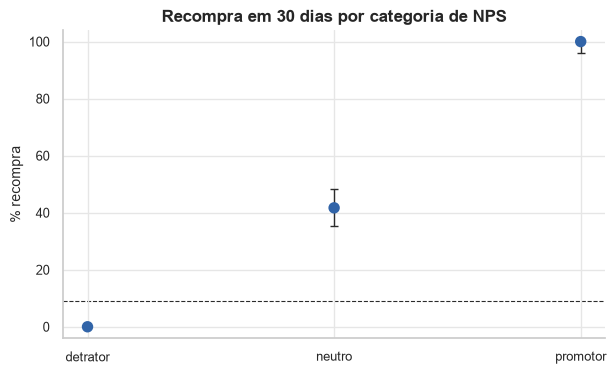

Correlação de Spearman entre CSAT e nota de NPS: 0.58 (p-valor 5e-178)


,pedidos,% recompra,IC inferior,IC superior,CSAT mediano
nps_category,,,,,
detrator,1687,0.0,0.0,0.2,2.3
neutro,223,41.7,35.4,48.3,5.2
promotor,90,100.0,95.9,100.0,6.3


In [3]:
repurchase = rate_table(train, "nps_category", target="repeat_purchase_30d").drop(columns="NPS")

fig, ax = plt.subplots(figsize=(7, 4))
plot_rate(
    repurchase,
    ax=ax,
    reference=100 * train["repeat_purchase_30d"].mean(),
    title="Recompra em 30 dias por categoria de NPS",
)
save_figure(fig, "02_recompra_por_categoria")
plt.show()

rho, p_value = stats.spearmanr(train["csat_internal_score"], train["nps_score"])
print(f"Correlação de Spearman entre CSAT e nota de NPS: {rho:.2f} (p-valor {p_value:.1g})")
csat = train.groupby("nps_category", observed=True)["csat_internal_score"].median()
repurchase.assign(**{"CSAT mediano": csat}).round(1)


**A recompra acompanha a categoria de NPS sem exceção: nenhum detrator volta a comprar em até 30 dias, e todos os promotores voltam.** Entre os neutros, cerca de quatro em cada dez recompram, e o CSAT sobe na mesma ordem das categorias, com associação moderada à nota, o que torna real o risco de vazamento que o mantém fora do modelo (D-06). A nota se sustenta como variável-alvo, embora uma separação tão exata seja mais um sinal da base simulada (D-10) do que evidência do valor do NPS numa operação real.

## 3. As falhas da jornada

Com que frequência cada falha acontece e quantas o mesmo pedido acumula. São as quatro falhas do `friction_score`: atraso, nova tentativa de entrega, contato com o atendimento e resolução acima de 7 dias. A frequência natural, em quantos pedidos a cada 10, é a forma de apresentar o resultado ao negócio.

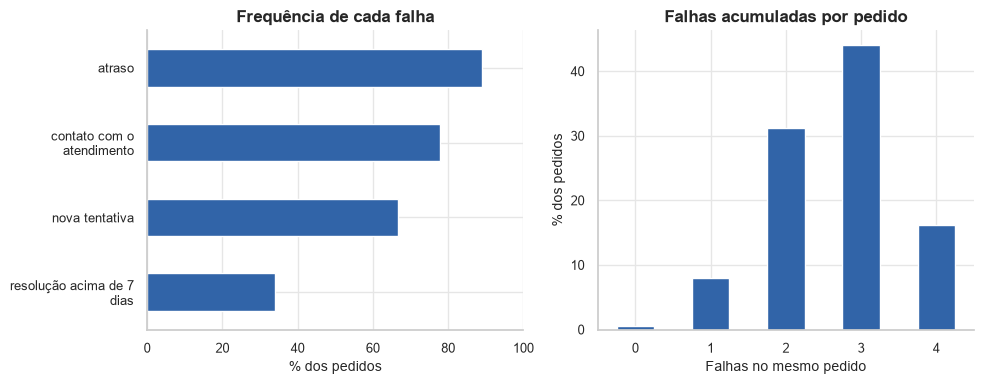

In [5]:
flags = failure_flags(train)

frequency = pd.DataFrame({
    "pedidos com a falha (%)": flags.mean().mul(100),
    "a cada 10 pedidos": flags.mean().mul(10),
})

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

frequency["pedidos com a falha (%)"].sort_values().plot.barh(
    ax=axes[0], color=ACCENT
)
axes[0].set_yticklabels([
    textwrap.fill(label.get_text(), width=24, max_lines=2)
    for label in axes[0].get_yticklabels()
])
axes[0].set_xlim(0, 100)
axes[0].set_xlabel("% dos pedidos")
axes[0].set_title("Frequência de cada falha")

train["friction_score"].value_counts(normalize=True).sort_index().mul(100).plot.bar(
    ax=axes[1], color=ACCENT, rot=0
)
axes[1].set_xlabel("Falhas no mesmo pedido")
axes[1].set_ylabel("% dos pedidos")
axes[1].set_title("Falhas acumuladas por pedido")

fig.tight_layout()
save_figure(fig, "03_falhas_da_jornada")
plt.show()


**A falha é a norma nesta jornada: o atraso atinge quase nove em cada dez pedidos, e o pedido típico acumula três das quatro falhas.** O contato com o atendimento vem logo atrás, com quase oito em cada dez pedidos, seguido da nova tentativa de entrega, com dois em cada três, e da resolução acima de 7 dias, com um em cada três. Pedido sem nenhuma falha é raro demais para servir de referência, e, com falhas tão disseminadas, a frequência sozinha não define prioridade: falta medir quanto cada falha eleva o risco de detrator em relação à sua ausência, o que a seção 5 faz.

## 4. Fatores mais críticos para a satisfação

A correlação de Spearman de cada variável numérica com a nota serve de mapa inicial, não de conclusão. Em seguida, cada variável de cadastro, pedido, entrega e atendimento entra em faixas com sentido de negócio, com a proporção de detratores e o NPS por faixa. O V de Cramér mede o tamanho do efeito e ordena os fatores; o p-valor do qui-quadrado é corrigido por Holm, porque são quinze testes. Fatores construídos um a partir do outro, como o atraso e as falhas acumuladas, que o incluem, são lidos em conjunto, para não contar o mesmo efeito duas vezes.

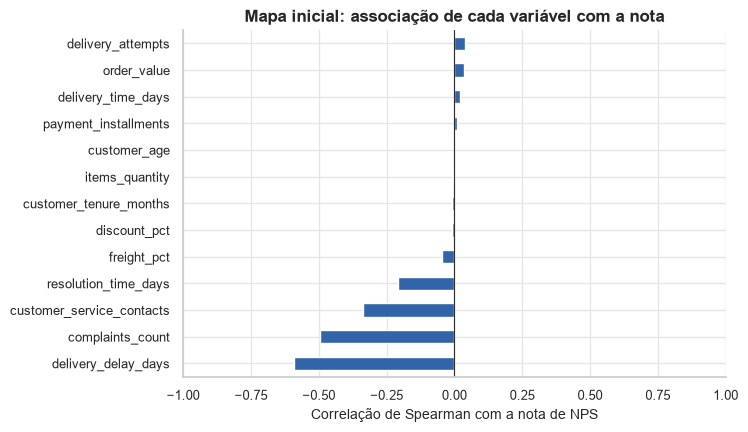

In [6]:
numeric_columns = [
    "delivery_delay_days",
    "delivery_time_days",
    "delivery_attempts",
    "customer_service_contacts",
    "resolution_time_days",
    "complaints_count",
    "freight_pct",
    "discount_pct",
    "order_value",
    "items_quantity",
    "payment_installments",
    "customer_age",
    "customer_tenure_months",
]
spearman = train[numeric_columns].corrwith(train["nps_score"], method="spearman").sort_values()

fig, ax = plt.subplots(figsize=(7, 4.5))
spearman.plot.barh(ax=ax, color=ACCENT)
ax.axvline(0, color="#2B2B2B", lw=0.8)
ax.set_xlim(-1, 1)
ax.set_xlabel("Correlação de Spearman com a nota de NPS")
ax.set_title("Mapa inicial: associação de cada variável com a nota")
plt.show()


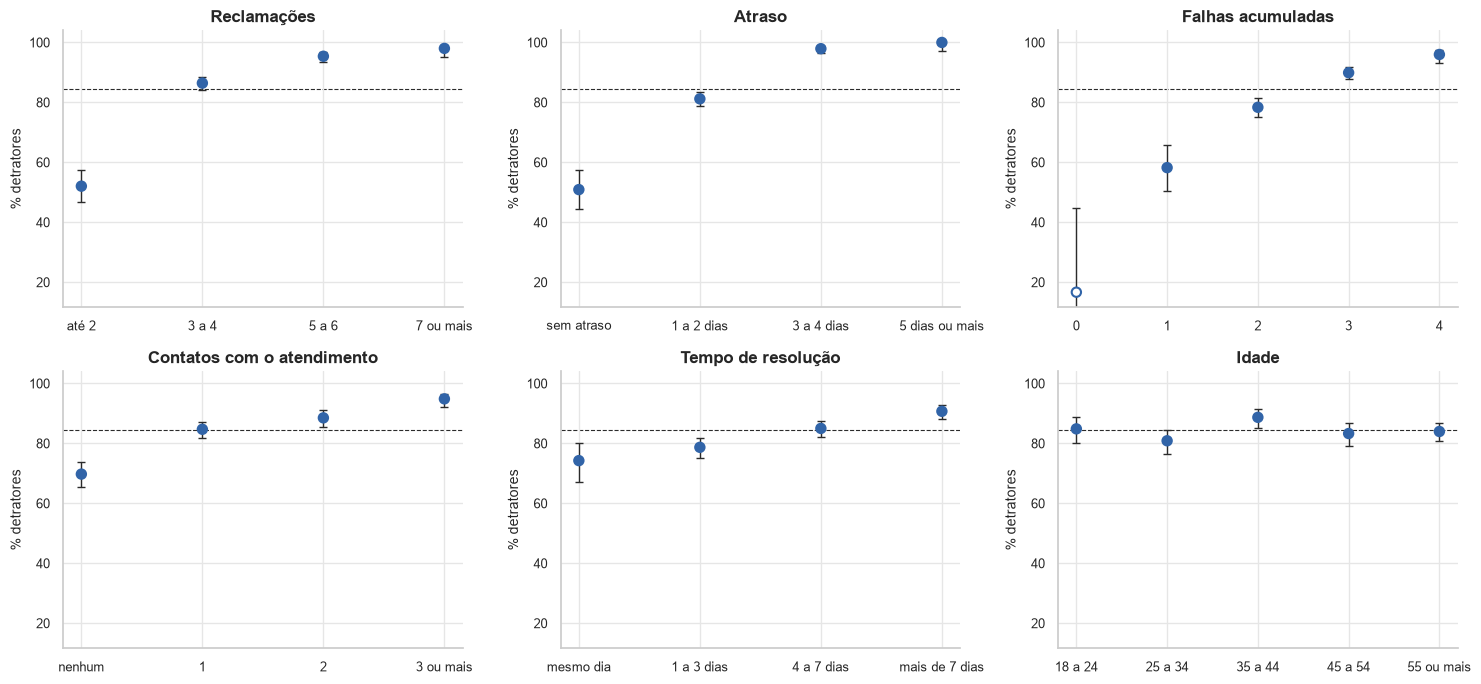

,V de Cramér,p ajustado,faixa com mais detratores,faixa com menos detratores,diferença (pontos)
fator,,,,,
reclamações,0.422,0.000,7 ou mais,até 2,45.973
atraso,0.393,0.000,5 dias ou mais,sem atraso,49.099
falhas acumuladas,0.312,0.000,4,1,37.760
contatos com o atendimento,0.235,0.000,3 ou mais,nenhum,25.107
tempo de resolução,0.153,0.000,mais de 7 dias,mesmo dia,16.456
idade,0.069,0.426,35 a 44,25 a 34,7.823
tentativas de entrega,0.065,0.140,2,3 ou mais,5.811
valor do pedido,0.056,0.778,Q1 (menor),Q4 (maior),5.400
frete relativo,0.043,1.000,Q3,Q1 (menor),3.400


In [ ]:
# Faixas fixadas antes de ver os resultados: limites de negócio ou quartis do treino
factors = {
    "atraso": train["delay_bucket"],
    "previsão de entrega": pd.cut(
        train["delivery_time_days"],
        [-np.inf, 4, 7, 10, np.inf],
        labels=["até 4 dias", "5 a 7 dias", "8 a 10 dias", "11 dias ou mais"],
    ),
    "tentativas de entrega": pd.cut(
        train["delivery_attempts"], [-np.inf, 1, 2, np.inf], labels=["1", "2", "3 ou mais"]
    ),
    "contatos com o atendimento": pd.cut(
        train["customer_service_contacts"],
        [-np.inf, 0, 1, 2, np.inf],
        labels=["nenhum", "1", "2", "3 ou mais"],
    ),
    "tempo de resolução": pd.cut(
        train["resolution_time_days"],
        [-np.inf, 0, 3, 7, np.inf],
        labels=["mesmo dia", "1 a 3 dias", "4 a 7 dias", "mais de 7 dias"],
    ),
    "reclamações": pd.cut(
        train["complaints_count"],
        [-np.inf, 2, 4, 6, np.inf],
        labels=["até 2", "3 a 4", "5 a 6", "7 ou mais"],
    ),
    "falhas acumuladas": train["friction_score"],
    "frete relativo": quartiles(train["freight_pct"]),
    "desconto relativo": quartiles(train["discount_pct"]),
    "valor do pedido": quartiles(train["order_value"]),
    "itens": pd.cut(
        train["items_quantity"], [-np.inf, 1, 3, np.inf], labels=["1", "2 a 3", "4 ou mais"]
    ),
    "parcelas": pd.cut(
        train["payment_installments"],
        [-np.inf, 1, 3, 6, np.inf],
        labels=["à vista", "2 a 3", "4 a 6", "7 ou mais"],
    ),
    "região": train["customer_region"],
    "idade": train["age_bucket"],
    "tempo de relacionamento": train["tenure_bucket"],
}
ranking = factor_ranking(train, factors)

# Os seis fatores de maior efeito, com a proporção de detratores em cada faixa
fig = plot_rates(
    {name.capitalize(): rate_table(train, factors[name]) for name in ranking.index[:6]},
    reference=100 * prevalence
)
save_figure(fig, "04_fatores_criticos")
plt.show()

ranking.round(3)


**Todo fator associado à satisfação está na entrega ou no atendimento, com reclamações e atraso à frente, quase empatados.** Nos dois, a proporção de detratores vai de metade dos clientes, no prazo ou com até duas reclamações, a quase todos a partir de três dias de atraso ou cinco reclamações; contatos e tempo de resolução seguem a mesma direção, com efeito menor, e o mapa de Spearman aponta as mesmas variáveis. Perfil do cliente, valor e condições do pedido, previsão de entrega e número de tentativas não mostram associação depois da correção, e, como a reclamação é expressão da insatisfação, e não uma falha a corrigir, o atraso é o fator de maior peso sob controle da operação.

## 5. O que mais gera detratores

Para cada falha, o impacto, que é a proporção de detratores com a falha dividida pela proporção sem ela, e a presença entre os detratores, que é a parcela deles que passou pela falha. A matriz impacto × presença separa o problema grave e comum, que é prioridade, do grave e raro. Como o contato com o atendimento costuma ser sintoma de outra falha, o efeito do contato também é medido só nos pedidos sem atraso. Por fim, uma árvore de decisão rasa, de profundidade 2, resume as combinações de fatores em regras legíveis.

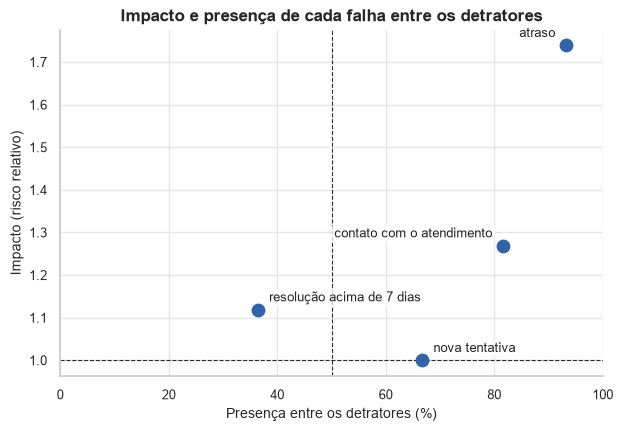

Pedidos sem atraso, com contato menos sem contato: +38.7 pontos (IC 95% de +24.3 a +51.5; menor grupo com 55 pedidos)


,pedidos com a falha (%),% detratores com,% detratores sem,impacto,presença entre detratores (%),pedidos sem a falha
atraso,88.90,88.53,50.90,1.74,93.30,222.0
nova tentativa,66.75,84.34,84.36,1.00,66.75,665.0
contato com o atendimento,77.85,88.50,69.75,1.27,81.68,443.0
resolução acima de 7 dias,33.90,90.71,81.09,1.12,36.46,1322.0


In [ ]:
impact = problem_impact(train, flags)

fig, ax = plt.subplots(figsize=(7, 4.5))
plot_impact_frequency(impact, ax=ax, title="Impacto e presença de cada falha entre os detratores")
save_figure(fig, "05_impacto_e_presenca")
plt.show()

# Contato com o atendimento sem a influência do atraso
contact_effect = estimate_contrast(
    train.query("delivery_delay_days == 0"), ["had_contact == 1", "had_contact == 0"], [1, -1]
)
print(
    f"Pedidos sem atraso, com contato menos sem contato: {contact_effect['efeito']:+.1f} pontos "
    f"(IC 95% de {contact_effect['IC inferior']:+.1f} a {contact_effect['IC superior']:+.1f}; "
    f"menor grupo com {contact_effect['menor grupo']} pedidos)"
)
impact.round(2)


In [11]:
# Árvore exploratória: regras legíveis, não um modelo; cada folha com pelo menos 50 pedidos
tree = DecisionTreeClassifier(max_depth=2, min_samples_leaf=50, random_state=RANDOM_SEED)
tree.fit(train[numeric_columns], train["is_detractor"])
tree_leaves(tree, train[numeric_columns], train["is_detractor"]).round(1)


,regra,pedidos,% detratores
0,complaints_count ≥ 3 e delivery_delay_days ≥ 2,1141,96.8
1,complaints_count ≤ 2 e delivery_delay_days ≥ 3,65,89.2
2,complaints_count ≥ 3 e delivery_delay_days ≤ 1,517,78.3
3,complaints_count ≤ 2 e delivery_delay_days ≤ 2,277,43.3


**O atraso é a falha prioritária: mais de nove em cada dez detratores passaram por ele, e a proporção de detratores sobe de metade, nos pedidos no prazo, para quase nove em cada dez nos atrasados.** O contato com o atendimento também fica no quadrante de prioridade, e o efeito dele resiste nos pedidos sem atraso, com intervalo largo, por causa do grupo pequeno, mas longe de zero; já a nova tentativa de entrega é comum e não muda o risco, e a resolução acima de 7 dias pesa pouco. A árvore separa os grupos só com reclamações e atraso: três reclamações ou mais com dois dias de atraso ou mais reúnem mais da metade dos pedidos, quase todos detratores, e só com até duas reclamações e até dois dias de atraso, cerca de um em cada sete pedidos, o detrator deixa de ser maioria.

## 6. Existe um ponto de ruptura?

A proporção de detratores por dia de atraso, com a faixa de confiança de 95%, mostra se o risco cresce aos poucos ou salta a partir de um limite. As mesmas curvas valem para tempo de resolução, contatos e tentativas. Uma árvore de profundidade 1 encontra o melhor corte de cada variável, e o AIC compara um modelo com esse corte a um modelo linear. Como o corte é escolhido nos próprios dados, ele conta como um parâmetro a mais. O salto se confirma se o corte reduz o AIC em 2 pontos ou mais; o crescimento é gradual se o modelo linear vence pela mesma margem; entre os dois, a forma fica indefinida.

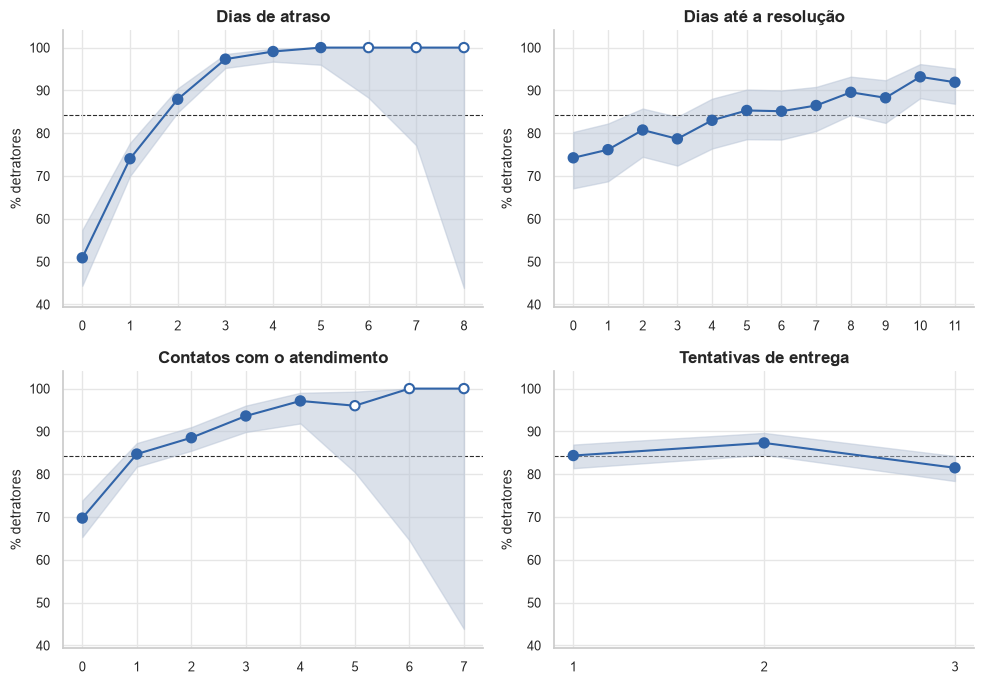

,a partir de,AIC linear,AIC com corte,ganho,forma
Dias de atraso,2.0,1389.1,1491.6,-102.5,gradual
Dias até a resolução,5.0,1690.5,1704.2,-13.7,gradual
Contatos com o atendimento,1.0,1632.2,1660.1,-27.8,gradual
Tentativas de entrega,3.0,1737.1,1735.0,2.1,salto


In [ ]:
curves = {
    "delivery_delay_days": "Dias de atraso",
    "resolution_time_days": "Dias até a resolução",
    "customer_service_contacts": "Contatos com o atendimento",
    "delivery_attempts": "Tentativas de entrega",
}
fig = plot_rates(
    {label: rate_table(train, column) for column, label in curves.items()},
    ncols=2,
    kind="line",
    reference=100 * prevalence,
)
save_figure(fig, "06_pontos_de_ruptura")
plt.show()

shape = {"confirmada": "salto", "refutada": "gradual", "inconclusiva": "indefinido"}
breakpoints = pd.DataFrame(
    {label: breakpoint_test(train, column) for column, label in curves.items()}
).T
breakpoints["forma"] = breakpoints["ganho"].map(verdict_breakpoint).map(shape)
breakpoints.round(1)


**Não há ponto de ruptura no atraso: cada dia conta, e a proporção de detratores sobe de metade, no prazo, para três em cada quatro com um dia de atraso e quase todos a partir do terceiro.** Com o tempo de resolução e com os contatos, o risco também cresce aos poucos, sem salto, e as curvas deixam de sustentar leitura a partir de seis dias de atraso e de cinco contatos, onde cada ponto tem menos de 30 pedidos. Nas tentativas de entrega, o salto apontado pela regra é uma pequena queda do risco na terceira tentativa, com ganho no limite da margem e numa variável que não mostrou associação na seção 4: não serve como limite de tolerância para a operação.

## 7. Interações entre fatores

Mapas de calor da proporção de detratores por duas variáveis, com o número de pedidos de cada célula entre parênteses. Os pares respondem a perguntas da operação: o atendimento salva uma entrega atrasada? Clientes antigos toleram mais o atraso (H4)? Frete caro somado a atraso é o pior caso (H5)? Desconto compensa uma falha (H6)? Nos três últimos pares, o atraso se divide em curto, de até 2 dias, e longo, a partir de 3, que reúne as duas faixas mais altas da `delay_bucket`. Células com menos de 30 pedidos não sustentam conclusão.

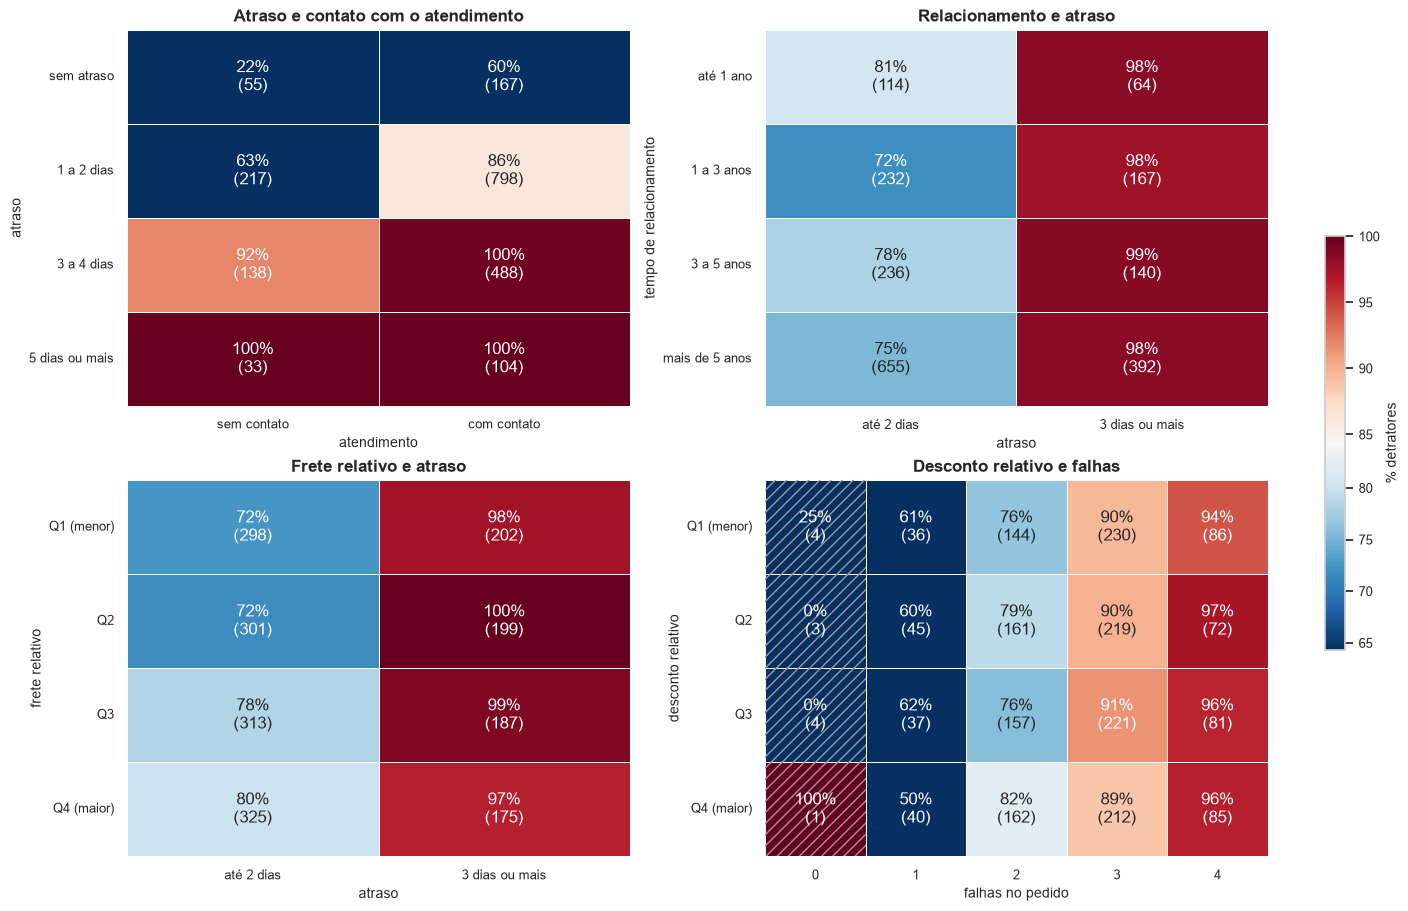

In [ ]:
delay_split = pd.cut(
    train["delivery_delay_days"], [-np.inf, 2, np.inf], labels=["até 2 dias", "3 dias ou mais"]
).rename("atraso")
contact = (
    train["had_contact"]
    .map({0: "sem contato", 1: "com contato"})
    .astype(pd.CategoricalDtype(["sem contato", "com contato"]))
    .rename("atendimento")
)
pairs = {
    "Atraso e contato com o atendimento": (train["delay_bucket"].rename("atraso"), contact),
    "Relacionamento e atraso": (
        train["tenure_bucket"].rename("tempo de relacionamento"),
        delay_split,
    ),
    "Frete relativo e atraso": (
        quartiles(train["freight_pct"]).rename("frete relativo"),
        delay_split,
    ),
    "Desconto relativo e falhas": (
        quartiles(train["discount_pct"]).rename("desconto relativo"),
        train["friction_score"].rename("falhas no pedido"),
    ),
}
fig = plot_rate_heatmaps(pairs, train["is_detractor"])
save_figure(fig, "07_interacoes")
plt.show()


**O atendimento não salva a entrega atrasada: em nenhuma faixa de atraso o pedido com contato tem menos detratores, e só no pedido no prazo e sem contato, um grupo pequeno, o detrator é minoria, cerca de um em cada cinco.** Tempo de relacionamento e frete não mudam o efeito do atraso, e, com três dias ou mais, mais de nove em cada dez clientes são detratores em qualquer faixa; o desconto também não altera a subida do risco com o número de falhas. As diferenças que restam, como a do maior desconto num pedido com uma só falha, ficam para os vereditos de H4, H5 e H6, na seção 9, e a coluna sem falhas não sustenta leitura, com menos de 30 pedidos por célula.

## 8. Que cliente tem NPS mais alto ou mais baixo

NPS e proporção de detratores por região, idade, tempo de relacionamento, valor do pedido e parcelamento. Para separar quem o cliente é do que aconteceu com ele, a proporção de detratores de cada região também é ajustada pelo atraso, por padronização direta: se a diferença entre regiões some com o ajuste, ela vem da logística, e não do perfil (H7). Personas por clusterização ficam de fora: com distribuições planas (D-10), grupos automáticos refletiriam a forma como a base foi gerada, e não perfis reais.

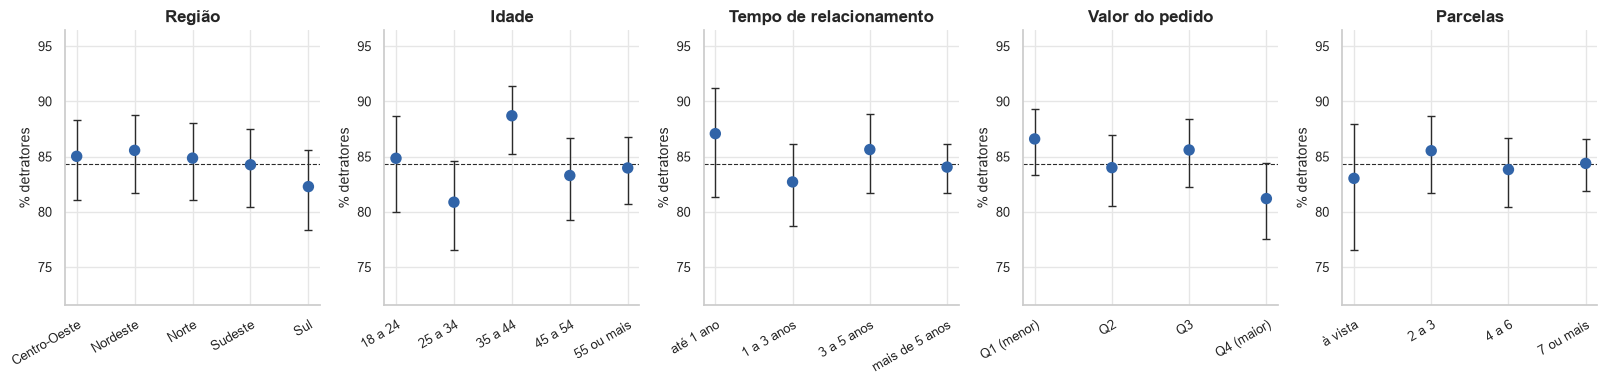

pedidos  % detratores  IC inferior  \
região                  Centro-Oeste        374          85.0         81.1   
                        Nordeste            381          85.6         81.7   
                        Norte               403          84.9         81.0   
                        Sudeste             413          84.3         80.4   
                        Sul                 429          82.3         78.4   
idade                   18 a 24             264          84.8         80.0   
                        25 a 34             366          80.9         76.5   
                        35 a 44             407          88.7         85.3   
                        45 a 54             389          83.3         79.3   
                        55 ou mais          574          84.0         80.7   
tempo de relacionamento até 1 ano           178          87.1         81.4   
                        1 a 3 anos          399          82.7         78.7   
                        3 a 5 anos          376          85.6         81.7   
                        mais de 5 anos     1047          84.0         81.7   
valor do pedido         Q1 (menor)          500          86.6         83.3   
                        Q2                  500          84.0         80.5   
                        Q3                  500          85.6         82.3   
                        Q4 (maior)          500          81.2         77.5   
parcelas                à vista             165          83.0         76.6   
                        2 a 3               394          85.5         81.7   
                        4 a 6               538          83.8         80.5   
                        7 ou mais           903          84.4         81.9   

                                        IC superior   NPS  
região                  Centro-Oeste           88.3 -79.9  
                        Nordeste               88.7 -80.6  
                        Norte                  88.0 -81.4  
                        Sudeste                87.5 -80.1  
                        Sul                    85.6 -77.4  
idade                   18 a 24                88.7 -79.5  
                        25 a 34                84.6 -75.4  
                        35 a 44                91.4 -85.0  
                        45 a 54                86.7 -79.7  
                        55 ou mais             86.7 -79.3  
tempo de relacionamento até 1 ano              91.2 -82.6  
                        1 a 3 anos             86.1 -78.2  
                        3 a 5 anos             88.8 -82.4  
                        mais de 5 anos         86.1 -79.1  
valor do pedido         Q1 (menor)             89.3 -83.4  
                        Q2                     87.0 -78.8  
                        Q3                     88.4 -81.6  
                        Q4 (maior)             84.4 -75.6  
parcelas                à vista                88.0 -77.6  
                        2 a 3                  88.7 -81.2  
                        4 a 6                  86.7 -78.6  
                        7 ou mais              86.6 -80.4

,pedidos,% detratores,IC inferior,IC superior,NPS,% ajustado pelo atraso
customer_region,,,,,,
Centro-Oeste,374,85.0,81.1,88.3,-79.9,85.0
Nordeste,381,85.6,81.7,88.7,-80.6,85.8
Norte,403,84.9,81.0,88.0,-81.4,85.2
Sudeste,413,84.3,80.4,87.5,-80.1,83.1
Sul,429,82.3,78.4,85.6,-77.4,83.0


In [ ]:
profiles = {
    "região": train["customer_region"],
    "idade": train["age_bucket"],
    "tempo de relacionamento": train["tenure_bucket"],
    "valor do pedido": factors["valor do pedido"],
    "parcelas": factors["parcelas"],
}
fig = plot_rates(
    {name.capitalize(): rate_table(train, band) for name, band in profiles.items()},
    ncols=5,
    reference=100 * prevalence,
    rotation=30,
    panel_size=(3.25, 4),
)
save_figure(fig, "08_perfis_de_cliente")
plt.show()

display(pd.concat({name: rate_table(train, band) for name, band in profiles.items()}).round(1))

regions = rate_table(train, "customer_region")
regions["% ajustado pelo atraso"] = standardized_share(train, "customer_region", "delay_bucket")
regions.round(1)


**Quem o cliente é quase não muda o risco: em todos os perfis, entre oito e nove em cada dez clientes são detratores.** A maior diferença, de cerca de oito pontos entre as faixas de 25 a 34 e de 35 a 44 anos, não segue um padrão ao longo da idade e não resistiu à correção da seção 4, e região, tempo de relacionamento, valor do pedido e parcelamento ficam a poucos pontos da média. Entre as regiões, o ajuste pelo atraso mantém o quadro, porque não há diferença regional para a logística explicar (H7): o risco acompanha o que aconteceu com o pedido, e não quem é o cliente.

## 9. Veredito das hipóteses

Cada hipótese do [entendimento do negócio](../reports/entendimento_negocio.md#8-hipóteses-para-a-análise-exploratória) recebe um veredito por uma regra fixada antes de ver os resultados. O efeito é medido em pontos percentuais de detratores, com intervalo bootstrap de 95%, e os p-valores são corrigidos por Holm.

- **Efeito previsto (H1a, H2, H3, H4, H5 e H8):** confirmada se o efeito tem pelo menos 5 pontos na direção prevista, com intervalo acima de zero e p ajustado abaixo de 0,05; refutada se o intervalo inteiro fica abaixo de 5 pontos; inconclusiva nos demais casos ou com algum grupo abaixo de 30 pedidos.
- **Salto (H1b):** confirmada se o modelo com corte reduz o AIC em 2 pontos ou mais em relação ao linear; refutada se o aumenta em 2 pontos ou mais.
- **Desconto (H6):** a hipótese de que o desconto não compensa falha é o contrário da hipótese de que ele reduz detratores em pelo menos 5 pontos nos pedidos com falha.
- **Região (H7):** confirmada se a diferença entre regiões, significativa sem ajuste, deixa de ser com o atraso no modelo; refutada se persiste; inconclusiva se não há diferença a explicar.
- **Detratores sem falha (H9):** confirmada se o intervalo da parcela de detratores sem nenhuma das quatro falhas fica todo em 10% ou mais; refutada se fica todo abaixo.

In [ ]:
# Grupos de cada comparação; os pesos somam as proporções de detratores de cada grupo
late, on_time = "delivery_delay_days >= 3", "delivery_delay_days <= 2"
long_resolution = f"resolution_time_days > {LONG_RESOLUTION_DAYS}"
data = train.assign(
    freight=quartiles(train["freight_pct"]), discount=quartiles(train["discount_pct"])
)

# H3: cada efeito medido com o outro fixo, para um não carregar o peso do outro
resolution_groups, resolution_weights = within_strata(
    data,
    long_resolution,
    f"not ({long_resolution})",
    [
        "customer_service_contacts == 0",
        "customer_service_contacts == 1",
        "customer_service_contacts >= 2",
    ],
)
contact_groups, contact_weights = within_strata(
    data,
    "customer_service_contacts >= 2",
    "customer_service_contacts <= 1",
    [long_resolution, f"not ({long_resolution})"],
)
contrasts = {
    "H1a": (
        "atraso de 5 dias ou mais menos sem atraso",
        ["delay_bucket == '5 dias ou mais'", "delay_bucket == 'sem atraso'"],
        [1, -1],
    ),
    "H2": (
        "sem atraso: mais de uma tentativa menos uma",
        [
            "delivery_delay_days == 0 and delivery_attempts > 1",
            "delivery_delay_days == 0 and delivery_attempts == 1",
        ],
        [1, -1],
    ),
    "H3": (
        "efeito da resolução longa menos o de 2 contatos ou mais, cada um com o outro fixo",
        resolution_groups + contact_groups,
        resolution_weights + [-weight for weight in contact_weights],
    ),
    "H4": (
        "efeito do atraso em clientes de até 1 ano menos em clientes de mais de 5 anos",
        [
            f"tenure_bucket == 'até 1 ano' and {late}",
            f"tenure_bucket == 'até 1 ano' and {on_time}",
            f"tenure_bucket == 'mais de 5 anos' and {late}",
            f"tenure_bucket == 'mais de 5 anos' and {on_time}",
        ],
        [1, -1, -1, 1],
    ),
    "H5": (
        "efeito do atraso no maior quartil de frete menos no menor",
        [
            f"freight == 'Q4 (maior)' and {late}",
            f"freight == 'Q4 (maior)' and {on_time}",
            f"freight == 'Q1 (menor)' and {late}",
            f"freight == 'Q1 (menor)' and {on_time}",
        ],
        [1, -1, -1, 1],
    ),
    "H6": (
        "com falha: menor quartil de desconto menos o maior",
        [
            "friction_score >= 1 and discount == 'Q1 (menor)'",
            "friction_score >= 1 and discount == 'Q4 (maior)'",
        ],
        [1, -1],
    ),
}
effects = {
    name: {"comparação": label, **estimate_contrast(data, groups, weights)}
    for name, (label, groups, weights) in contrasts.items()
}
effects["H8"] = {
    "comparação": "detratores com 2 falhas ou mais acima do previsto pela soma das falhas",
    **bootstrap_statistic(train, lambda d: excess_over_additive(d, failure_flags(d))),
    "menor grupo": int((train["friction_score"] >= 2).sum()),
}
effects = pd.DataFrame(effects).T
effects["p ajustado"] = multipletests(effects["p-valor"].astype(float), method="holm")[1]
effects["veredito"] = [
    verdict_effect(
        row["efeito"],
        row["IC inferior"],
        row["IC superior"],
        row["p ajustado"],
        row["menor grupo"],
    )
    for _, row in effects.iterrows()
]
# H6 afirma o contrário: o desconto não compensa a falha
effects.loc["H6", "veredito"] = invert_verdict(effects.loc["H6", "veredito"])


In [ ]:
# H1b: salto no atraso, pelo AIC do modelo com corte contra o linear
delay_break = breakpoint_test(train, "delivery_delay_days")
cut_label = f"a partir de {delay_break['a partir de']:.0f} dias"

# H7: diferença entre regiões antes e depois de pôr o atraso no modelo
# O atraso entra em dias e ao quadrado, para o efeito poder curvar
delay_terms = "delivery_delay_days + I(delivery_delay_days ** 2)"
null = smf.logit("is_detractor ~ 1", data=train).fit(disp=0)
region = smf.logit("is_detractor ~ C(customer_region)", data=train).fit(disp=0)
delay = smf.logit(f"is_detractor ~ {delay_terms}", data=train).fit(disp=0)
both = smf.logit(f"is_detractor ~ {delay_terms} + C(customer_region)", data=train).fit(disp=0)
p_crude = stats.chi2.sf(2 * (region.llf - null.llf), region.df_model)
p_adjusted = stats.chi2.sf(2 * (both.llf - delay.llf), both.df_model - delay.df_model)

# H9: parcela dos detratores sem nenhuma das quatro falhas
detractors = train[train["is_detractor"] == 1]
without_failure = int((detractors["friction_score"] == 0).sum())
low, high = proportion_confint(without_failure, len(detractors), method="wilson")

others = pd.DataFrame(
    {
        "H1b": {
            "comparação": f"ganho de AIC do corte {cut_label}",
            "efeito": delay_break["ganho"],
            "veredito": verdict_breakpoint(delay_break["ganho"]),
        },
        "H7": {
            "comparação": "p-valor das regiões sem ajuste e com o atraso no modelo",
            "p-valor": p_crude,
            "p ajustado": p_adjusted,
            "veredito": verdict_adjustment(p_crude, p_adjusted),
        },
        "H9": {
            "comparação": "% dos detratores sem nenhuma das quatro falhas",
            "efeito": 100 * without_failure / len(detractors),
            "IC inferior": 100 * low,
            "IC superior": 100 * high,
            "menor grupo": len(detractors),
            "veredito": verdict_share(100 * low, 100 * high, minimum=10),
        },
    }
).T
verdicts = pd.concat([effects, others]).sort_index()
verdicts[
    ["comparação", "efeito", "IC inferior", "IC superior", "p ajustado", "menor grupo", "veredito"]
]


,comparação,efeito,IC inferior,IC superior,p ajustado,menor grupo,veredito
H1a,atraso de 5 dias ou mais menos sem atraso,49.099099,42.32378,56.190476,0.0035,137,confirmada
H1b,ganho de AIC do corte a partir de 2 dias,-102.50204,NaN,NaN,NaN,NaN,refutada
H2,sem atraso: mais de uma tentativa menos uma,0.385132,-13.52954,14.325403,1.0,77,inconclusiva
H3,efeito da resolução longa menos o de 2 contato...,-3.151608,-7.428554,1.114064,0.72,143,refutada
H4,efeito do atraso em clientes de até 1 ano meno...,-5.313795,-14.080872,3.53839,0.952,64,refutada
H5,efeito do atraso no maior quartil de frete men...,-8.470102,-16.170772,-1.358019,0.114,175,refutada
H6,com falha: menor quartil de desconto menos o m...,-0.293733,-4.694728,4.426527,1.0,496,confirmada
H7,p-valor das regiões sem ajuste e com o atraso ...,NaN,NaN,NaN,0.5941,NaN,inconclusiva
H8,detratores com 2 falhas ou mais acima do previ...,-0.061121,-0.450922,0.336988,1.0,1830,refutada
H9,% dos detratores sem nenhuma das quatro falhas,0.118554,0.032518,0.431243,NaN,1687,refutada


**O risco de detrator acompanha as falhas, sobretudo o atraso (H1a), que pesa dia a dia, sem ponto de ruptura (H1b): o tempo de relacionamento não amortece esse efeito (H4), o frete caro não o agrava (H5) e o desconto não o compensa (H6).** As falhas se somam sem efeito extra (H8), a resolução longa não pesa mais que os contatos (H3) e quase nenhum detrator escapou das falhas (H9), resultado quase certo quando quase todo pedido tem alguma falha; H2 fica inconclusiva por intervalo largo num grupo pequeno, e H7, porque as regiões não diferem nem antes do ajuste. Ganham força as ações contra o atraso desde o primeiro dia e a correção da causa no lugar do cupom; perdem força as que dependiam de um ponto de ruptura, da prioridade ao cliente novo, da devolução do frete, de uma meta de resolução à frente do contato e de agir só na segunda falha.

## 10. Tamanho da oportunidade

Quanto o NPS mudaria se os pedidos atrasados tivessem a mesma mistura de detratores, neutros e promotores dos pedidos sem atraso. Um segundo cenário aplica a mesma troca só aos pedidos a partir do corte de atraso da seção 6. O ganho vem com intervalo bootstrap de 95%. É uma estimativa por associação, não uma promessa: dá a ordem de grandeza do ganho possível ao atacar o atraso.

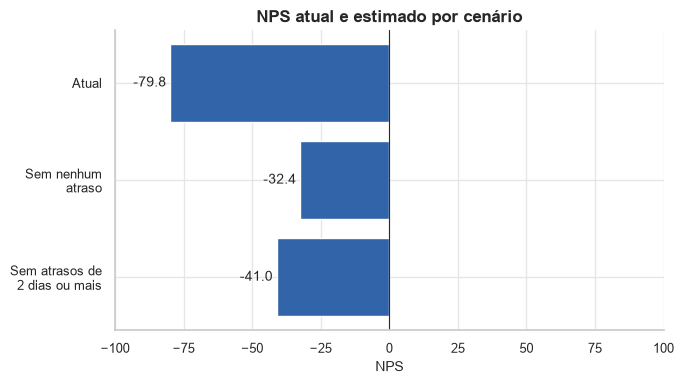

,NPS estimado,ganho (pontos),IC inferior,IC superior
Sem nenhum atraso,-32.4,47.4,38.3,57.2
Sem atrasos de 2 dias ou mais,-41.0,38.9,32.3,45.9


In [ ]:
# Em cada cenário, os pedidos afetados passam a ter a mistura dos pedidos sem atraso
reference = "delivery_delay_days == 0"
scenarios = {"Sem nenhum atraso": "delivery_delay_days > 0"}

cut = breakpoints.loc["Dias de atraso", "a partir de"]

if not np.isnan(cut):
    scenarios[f"Sem atrasos de {cut:.0f} dias ou mais"] = (
        f"delivery_delay_days >= {cut}"
    )

orders = train[["delivery_delay_days", "nps_category"]]

opportunity = pd.DataFrame(
    {
        name: bootstrap_statistic(
            orders,
            partial(nps_gain, affected=rule, reference=reference),
        )
        for name, rule in scenarios.items()
    }
).T.drop(columns="p-valor")

opportunity = opportunity.rename(columns={"efeito": "ganho (pontos)"})

current = nps_of(train["nps_category"])

opportunity.insert(
    0,
    "NPS estimado",
    current + opportunity["ganho (pontos)"],
)

nps = pd.concat(
    [
        pd.Series({"Atual": current}),
        opportunity["NPS estimado"],
    ]
)

labels = [
    textwrap.fill(label, width=15)
    for label in nps.index[::-1]
]

fig, ax = plt.subplots(figsize=(7, 4))

bars = ax.barh(
    labels,
    nps[::-1],
    color=ACCENT,
)

ax.bar_label(
    bars,
    fmt="%.1f",
    padding=3,
    fontsize=10,
)

ax.axvline(0, color="#2B2B2B", linewidth=0.8)
ax.set_xlim(-100, 100)
ax.set_xlabel("NPS")
ax.set_title("NPS atual e estimado por cenário")

fig.tight_layout()

save_figure(fig, "10_tamanho_da_oportunidade")
plt.show()

opportunity.round(1)


**Eliminar o atraso é a maior alavanca da base, mas não basta: mesmo sem nenhum atraso, o NPS continuaria negativo, e os detratores cairiam de mais de oito em cada dez para cerca de metade dos clientes.** Atacar só os atrasos de dois dias ou mais renderia cerca de quatro quintos desse ganho, e os intervalos dos dois cenários ficam longe de zero, mas largos o bastante para o número valer como ordem de grandeza. É um teto otimista: o cálculo supõe que o atraso, e não o que anda junto com ele, como reclamações e contatos, explica toda a diferença entre pedidos atrasados e no prazo.

## 11. Referências para o modelo

As regras simples que o modelo da Etapa 6 precisa superar, medidas no treino com as métricas da D-03: PR-AUC e o resultado de uma lista com os 20% de maior risco, em precisão e em captura de detratores. Entram o modelo ingênuo, que dá o mesmo risco a todos, duas regras que ordenam os clientes por uma única informação, dias de atraso e número de falhas, e a árvore rasa da seção 5, avaliada por validação cruzada para não ser medida nos mesmos pedidos que a criaram. A revisão usa esses números para decidir se as métricas da D-03 seguem adequadas e para fixar os alvos antes de qualquer treino.

In [ ]:
target = train["is_detractor"]
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
shallow_tree = DecisionTreeClassifier(max_depth=2, min_samples_leaf=50, random_state=RANDOM_SEED)
tree_risk = cross_val_predict(
    shallow_tree, train[numeric_columns], target, cv=folds, method="predict_proba"
)[:, 1]
scores = {
    "modelo ingênuo": np.zeros(len(target)),
    "dias de atraso": train["delivery_delay_days"],
    "falhas acumuladas": train["friction_score"],
    "árvore rasa": tree_risk,
}
pd.DataFrame({name: ranking_metrics(target, score) for name, score in scores.items()}).T.round(3)


,PR-AUC,ROC-AUC,precisão no topo,captura no topo
modelo ingênuo,0.844,0.500,0.840,0.199
dias de atraso,0.944,0.803,0.995,0.236
falhas acumuladas,0.907,0.705,0.958,0.227
árvore rasa,0.939,0.803,0.945,0.224


**Uma única informação, os dias de atraso, já é a melhor referência e encosta no teto: quase todos os clientes do topo da lista são detratores, e a captura fica praticamente no máximo que uma lista com 20% dos pedidos permite.** A árvore rasa, avaliada por validação cruzada, chega perto do atraso sem superá-lo em nenhuma métrica, e as falhas acumuladas ficam abaixo dos dois, coerente com uma soma que inclui a nova tentativa, falha que não muda o risco. Para o modelo da Etapa 6, sobra pouca margem sobre essa referência nas métricas da D-03, um pouco na PR-AUC e quase nenhuma na captura, e é esse limite que a revisão precisa enfrentar antes de fixar os alvos.